( [**TOC**](../TOC.md) | Next: [**2.1 Electrical Conduction and Diodes**](../chapter.2/chapter2.ipynb) )


**Chapter 1**

## Introduction

**By Abbas Kohan and M. B. Ghaznavi-Ghoushchi**

# 1.1 Electronic Circuit Theory

electronic devices such as diodes, triodes, and transistors operate as switches or valves to control or modulate the flow of electric current. Electronic switches and valves are useful because of their sensitivity and speed of operation, which exceed the sensitivity and speed of mechanical or electromechanical devices.
Electronic circuit theory is the mathematical study of circuits con- taining electronic devices. The ultimate purpose of electronic circuit theory is to provide a basis for the design of electronic systems. Such systems are combinations of electric and electronic devices assembled and connected to perform some desired operation on an electrical signal. These systems may also be associated with nonelectrical devices as in servomechanisms or industrial process control.
Like any other body of theory, electronic circuit theory deals with models. A model is a simple, idealized abstraction which approximates the behavior of a physical system. A model is always a compromise between simplicity and reality. The three phases of electronic circuit theory are, therefore, as follows:
1. Development of suitable circuit models for electronic devices. Model making is facilitated by a knowledge of the theoretical "models" for the

underlying physical processes which determine the externally observed electrical behavior of a given device.
2. Development of analysis methods applicable to electronic circuits. A natural and useful approach is the extension of elementary electric circuit theory so that familiar techniques can be brought to bear upon electronic circuits.
3. Accumulation of a store of ideas from working with the models and analyzing the circuits. A knowledge of device and circuit capabilities and limitations provides specific criteria and general technical intuition for the design of electronic systems.
This book emphasizes the first two phases of electronic circuit theory, namely, model making and methods of circuit analysis. Design informa- tion accumulates, as we proceed, from illustrative examples, problems, and interpretations of basic results.
# 1.2 Ideal Circuit Elements
In general, electronic circuits are not linear and do not obey reciprocity. This means that we cannot make satisfactory circuit models from the familiar R, L, and C building blocks of linear circuit theory. However, the difficulty can be overcome with only two additional circuit elements. These are the ideal diode and the controlled source.


Text(0.5, 1.0, 'Original')

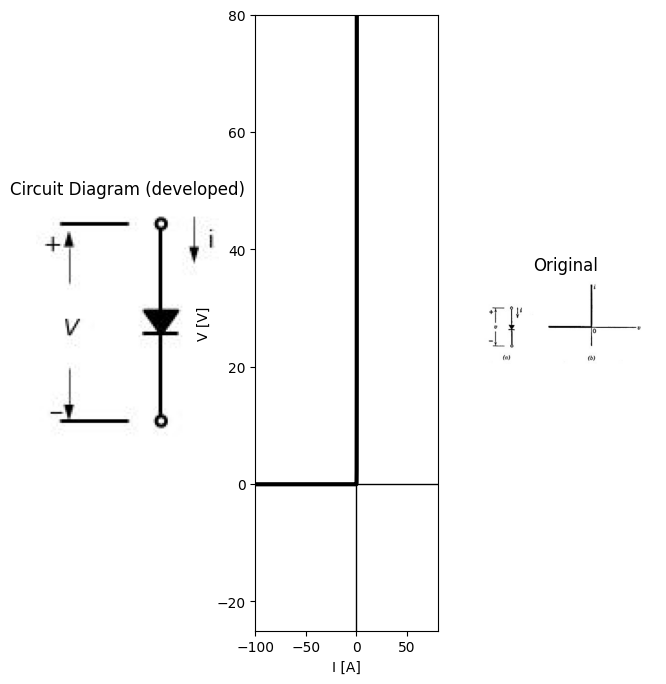

In [5]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as e
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

# Create the figure and subplots
fig, axs = plt.subplots(1, 3, figsize=(8, 8))
d = schemdraw.Drawing()
d.push()
D1 = d.add(e.Diode(fill=True).down().dot(open=True))
l1 = d.add(e.Line().right().length(.0004).dot(open=True).at(D1.start))
d += e.Arrow().down().linewidth(0.6).length(0.7).color('black').label('i', loc='bottom', color='black',ofst=0.2). at((0.5,0.1))
l2 = d.add(e.Line().right().length(1).at((-1.5,0)))
l3 = d.add(e.Line().right().length(1).at((-1.5,-3)))
d += e.Arrow().up().length(0.8).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((-1.4,-0.9))
d += e.Arrow().down().length(0.8).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((-1.4,-2.2))
d += e.Arrow().up().length(1).linewidth(0.6).color('white').label('$V$', loc='start', color='black',ofst=0.3). at((-0.9,-1.4))
d.save('Drawings/1-1a.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/1-1a.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 40@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 0.01@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '1', circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=3)

axs[1].set_xlim(-100, 80)
axs[1].set_xlabel('I [A]')
axs[1].set_ylabel('V [V]')
axs[1].set_ylim(-25, 80)
axs[1].axhline(0, color='black', linewidth=1)
axs[1].axvline(0, color='black', linewidth=1)

img_sample = mpimg.imread('images/fig1-1.jpg')  # Load the PNG file
axs[2].imshow(img_sample)
axs[2].axis('off')  # Hide axes for image display
axs[2].set_title('Original')

## Fig. 1.1. The ideal diode. (a) Circuit symbol; (6) Current versus voltage curve.

As indicated in Fig. 1.1, the ideal diode is a self-operated switch that
opens when the terminal voltage is negative and closes when the current is
positive. The ideal diode, sometimes called an ideal rectifier, is a non-
linear circuit element. It is an idealized approximation of the class of
electronic devices known as diodes or rectifiers.
A controlled source is shown in Fig. 1.2. The control variable and the

source variable may each be either a current or a voltage, but only the
current-controlled current source is shown here. The controlled source
is a linear three-terminal circuit element. It is described by the linear
two-terminal-pair relations between its input variables $e{1}$  and $i{1}$, and its
output variables $e{2}$ and $i{2}$. The controlled source is a basic unilateral
circuit element, ‘‘Unilateral” means that a signal at the input has an

Text(0.5, 1.0, 'Original')

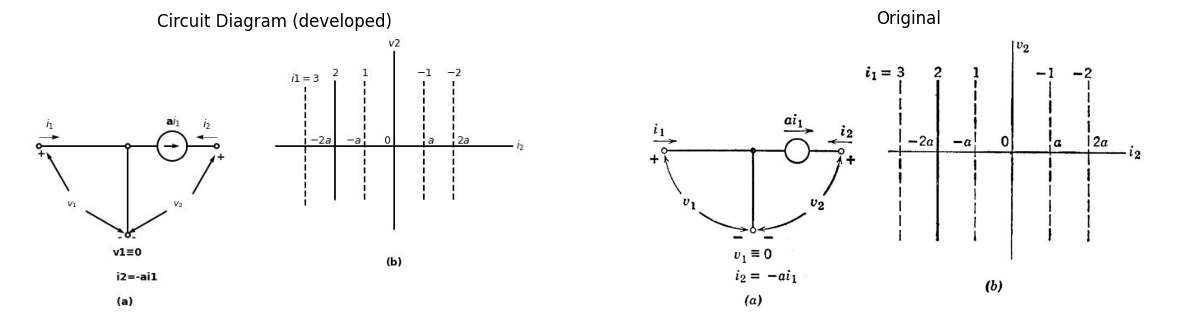

In [25]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(15, 15))
d = schemdraw.Drawing()
l1 = d.add(e.Line().right().length(.0004).dot(open=True))
l2 = d.add(e.Line().right().length(3).dot(open=True).at(l1.start))
I = d.add(e.SourceI(l=3).right().label('a$i_1$').dot(open=True)) 
l3 = d.add(e.Line().down().length(3).dot(open=True).at(I.start))
d += e.Arrow().length(1.5).at((5.2, -1.6)).label('+', ofst=(0.7,-0.4)).theta(60)
d += e.Arrow().length(1.5).at((4.3, -2.2)).label('-', ofst=(0.7,0.4)).theta(-150) 
d += e.Gap().right().label('$v_{2}$',fontsize = 12).color('black').at((3.2,-1.8))
d += e.Arrow().length(1.5).at((1.6, -2.2)).label('-', ofst=(0.7,-0.4)).theta(-30) 
d += e.Arrow().length(1.5).at((1, -1.5)).label('+', ofst=(0.7,0.4)).theta(120)
d += e.Gap().right().label('$v_{1}$',fontsize = 12).color('black').at((-0.4,-1.8))
d += e.Arrow().left().linewidth(0.6).length(0.7).color('black').label('$i_2$', loc='top', color='black',ofst=0.2).at((6,0.3))
d += e.Arrow().right().linewidth(0.6).length(0.7).color('black').label('$i_1$', loc='top', color='black',ofst=0.2).at((0,0.3))
l4 = d.add(e.Line().right().length(.4).at((2,-4)).label('\n\nv1≡0\n\n i2=-ai1\n\n (a)', 'right',color='black').color('white') )
l5 = d.add(e.Line().right().length(8).at((8,0)).label('$i_2$', 'right'))
l6 = d.add(e.Line().up().length(4).at((9,-2)).label('$i{1}=3$', 'right').linestyle('--'))
l7 = d.add(e.Line().up().length(4).at((10,-1.8)).label('$2$', 'right').linestyle('-').label('$-2a$', 'top'))
l8 = d.add(e.Line().up().length(4).at((11,-1.8)).label('$1$', 'right').linestyle('--').label('$-a$', 'top'))
l9 = d.add(e.Line().up().length(6).at((12,-2.8)).label('$v{2}$', 'right').linestyle('-').label('$0$', 'top').label('\n\n(b)', 'left'))
l10 = d.add(e.Line().up().length(4).at((13,-1.8)).label('$-1$', 'right').linestyle('--').label('$a$', 'bottom'))
l11 = d.add(e.Line().up().length(4).at((14,-1.8)).label('$-2$', 'right').linestyle('--').label('$2a$', 'bottom'))
d.save('Drawings/1-1a.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/1-1a.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/fig1-2.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

## Fig. 1.2. The controlled source. (a) Circuit symbol for a current-controlled current source; (b) Output curve (vg ve. 72) showing the effect of the control signal.

effect on the output but a signal applied at the output has no influence
on the input. Thus in Fig. 1.2, the input current 4, controls the position
of the line relating vz and ¢. Varying i, from +2 to —2 sweeps the
vg V8. 12 line across the plane from left to right. Conversely, v; and i
are independent of applied v2. Such performance is impossible to achieve
with resistance, capacitance, or inductance (including mutual induct-
ance), Coupling between two terminal-pairs due to any of these ele-
ments is “bilateral” or “reciprocal” (two-way coupling).

# 1.3 Circuit Models

The ideal diode allows us to make piecewise-linear models of nonlinear
devices. From the current-versus-voltage curve for a typical vacuum
diode [Fig. 1.3(a)], we see the general character of diode curves that
suggests the ideal-rectifier approximation. By combining just a single
resistance with an ideal diode, as in Fig. 1.3(b), we have a piecewise-
linear model that matches the actual curve very closely.
Inclusion of a controlled (or dependent) source allows us to devise
models that approximate the output curve of a control valve (such as a

Text(0, 0.5, 'ib [mA]')

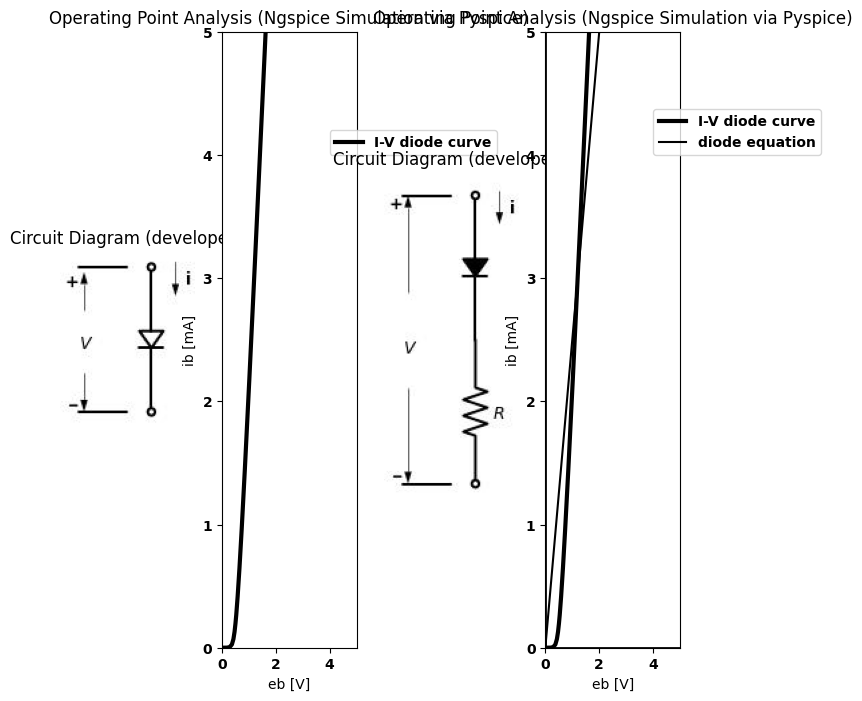

In [7]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

# Create the figure and subplots
fig, axs = plt.subplots(1,4, figsize=(8, 8))
d = schemdraw.Drawing()
D1 = d.add(e.Diode().down().dot(open=True))
l1 = d.add(e.Line().right().length(.0004).dot(open=True).at(D1.start))
d += e.Arrow().down().linewidth(0.6).length(0.7).color('black').label('i', loc='bottom', color='black',ofst=0.2). at((0.5,0.1))
l2 = d.add(e.Line().right().length(1).at((-1.5,0)))
l3 = d.add(e.Line().right().length(1).at((-1.5,-3)))
d += e.Arrow().up().length(0.8).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((-1.4,-0.9))
d += e.Arrow().down().length(0.8).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((-1.4,-2.2))
d += e.Arrow().up().length(1).linewidth(0.6).color('white').label('$V$', loc='start', color='black',ofst=0.3). at((-0.9,-1.4))
d.save('Drawings/1-3a.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/1-3a.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 14.5@u_nA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 200@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3)

axs[1].legend(('I-V diode curve','diode equation'), loc=(.8,.8))
axs[1].set_title('Operating Point Analysis (Ngspice Simulation via Pyspice)')

axs[1].set_xlim(0, 5)
axs[1].set_ylim(0, 5)
axs[1].set_xlabel('eb [V]')
axs[1].set_ylabel('ib [mA]')
d = schemdraw.Drawing()
D1 = d.add(e.Diode(fill=True).down())
R1 = d.add(e.Resistor().down().dot(open=True).label('$R$', 'bottom'))
l1 = d.add(e.Line().right().length(.0004).dot(open=True).at(D1.start))
l2 = d.add(e.Line().right().length(1).at((-1.5,0)))
l3 = d.add(e.Line().right().length(1).at((-1.5,-6)))
d += e.Arrow().up().length(2).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((-1.4,-2))
d += e.Arrow().down().length(2).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((-1.4,-4))
d += e.Arrow().up().length(1).linewidth(0.6).color('white').label('$V$', loc='start', color='black',ofst=0.3). at((-0.9,-3))
d += e.Arrow().down().linewidth(0.6).length(0.7).color('black').label('i', loc='bottom', color='black',ofst=0.2). at((0.5,0.1))
d.save('Drawings/1-3b.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/1-3b.jpg')
axs[2].imshow(img)
axs[2].axis('off')  # Hide axes for image display
axs[2].set_title('Circuit Diagram (developed)')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 14.5@u_nA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 200@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[3].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3)
# **Subplot (2, 1): First Matplotlib Chart (Sine Wave)**
I = np.linspace(-2, 10, 100)   
R1 =2.5  
R2 = .2   
Rs = R1+R2   
V1 = R1 * I  
V2 = R2 * I  
Vs = Rs * I   
axs[3].plot(I, V1, color='black', linestyle='-')   
axs[3].axhline(0, color='black', linewidth=2)
axs[3].axvline(0, color='black', linewidth=2) 
axs[3].legend(('I-V diode curve','diode equation'), loc=(.8,.8))
axs[3].set_title('Operating Point Analysis (Ngspice Simulation via Pyspice)')
axs[3].set_xlim(0, 5)
axs[3].set_ylim(0, 5)
axs[3].set_xlabel('eb [V]')
axs[3].set_ylabel('ib [mA]')
# **Subplot (1, 2): PNG Sample File**


![](images/fig1-3.jpg)

## Fig. 1.3. Diode curve and piecewise-linear approximation.


Text(0.5, 1.0, 'Original')

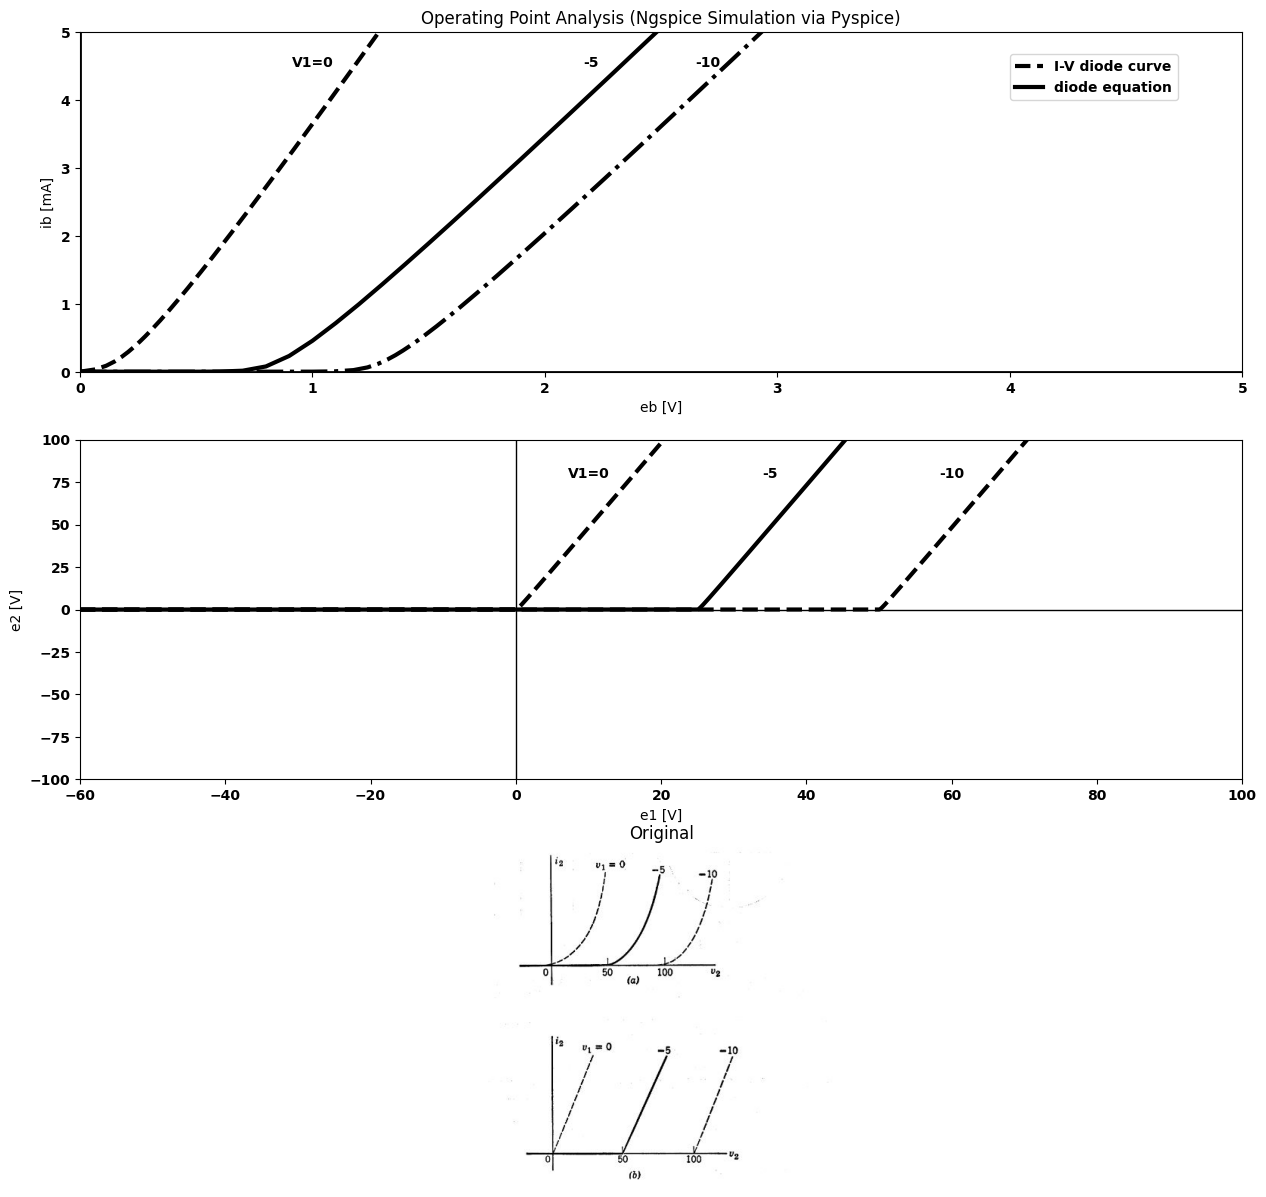

In [12]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

# Create the figure and subplots
fig, axs = plt.subplots(3,1, figsize=(15, 15))
rcParams['font.weight'] = 'bold'
# circuit 3
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 40@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 100@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2', '3' , model = 'BAV21')
circuit.R(1, '1', '2', 100@u_Ohm)
circuit.V('i', '3', circuit.gnd, 25@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=3)
# circuit 3
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 40@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 100@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2', circuit.gnd , model = 'BAV21')
circuit.R(1, '1', '2', 100@u_Ohm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=3,linestyle='--')
# circuit 3
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 40@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 100@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2', '3' , model = 'BAV21')
circuit.R(1, '1', '2', 100@u_Ohm)
circuit.V('i', '3', circuit.gnd, 50@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=3,linestyle='--')
axs[1].set_xlim(-60, 100)
axs[1].set_xlabel('e1 [V]')
axs[1].set_ylabel('e2 [V]')
axs[1].set_ylim(-100, 100)
axs[1].axhline(0, color='black', linewidth=1)
axs[1].axvline(0, color='black', linewidth=1)
axs[1].text( 10,80, 'V1=0', ha='center', va='center')
axs[1].text( 35, 80, '-5', ha='center', va='center')
axs[1].text(60,80, '-10', ha='center', va='center')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 14.5@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .8@u_V ,CJO = 7.048E-13 ,RS = 200@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, .10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='--')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1, '1', '2', 0@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-') 
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = .0010@u_pA , N = 1.906  ,BV = 210@u_V, IBV = 0.0001@u_V,  VJ = 1.3@u_V ,CJO = 7.048E-13 ,RS = 300@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=3,linestyle='-.')
axs[0].axhline(0, color='black', linewidth=2)
axs[0].axvline(0, color='black', linewidth=2) 
axs[0].legend(('I-V diode curve','diode equation'), loc=(.8,.8))
axs[0].set_title('Operating Point Analysis (Ngspice Simulation via Pyspice)')
axs[0].text( 1, 4.545, 'V1=0', ha='center', va='center')
axs[0].text( 2.2, 4.545, '-5', ha='center', va='center')
axs[0].text( 2.7, 4.545, '-10', ha='center', va='center')
axs[0].set_xlim(0, 5)
axs[0].set_ylim(0, 5)
axs[0].set_xlabel('eb [V]')
axs[0].set_ylabel('ib [mA]')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/fig1-4.jpg')  # Load the PNG file
axs[2].imshow(img_sample)
axs[2].axis('off')  # Hide axes for image display
axs[2].set_title('Original')

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

def plot_mosfet_curve(Vth=1.0, Kn=2e-3):
    Vgs = np.linspace(0, 3, 300)
    Id = Kn * np.maximum(Vgs - Vth, 0) ** 2

    plt.figure(figsize=(10,6))
    plt.plot(Vgs, Id*1e3, color='black', linewidth=3, label=r'$I_D$ vs $V_{GS}$')
    plt.xlabel('Gate-Source Voltage $V_{GS}$ (V)', fontsize=16)
    plt.ylabel('Drain Current $I_D$ (mA)', fontsize=16)
    plt.title('Common Source MOSFET Output Current', fontsize=16)
    plt.legend(fontsize=14)
    #plt.grid(True)
    plt.ylim(bottom=0)
    plt.show()

# Create interactive sliders for Vth and Kn
interact(
    plot_mosfet_curve,
    Vgs=FloatSlider(value=1.0, min=0.5, max=2.5, step=0.05, description='vgs (V)'),
    Kn=FloatSlider(value=2e-3, min=0.5e-3, max=5e-3, step=1e-3, description='Kn (A/V²)')
)


interactive(children=(FloatSlider(value=1.0, description='Vth', max=3.0, min=-1.0), FloatSlider(value=0.002, d…

<function __main__.plot_mosfet_curve(Vth=1.0, Kn=0.002)>

## Fig. 1.4. Control valve curve and piecewise-linear approximation. (a) ig va. v2 for a = —5; (b) Approximation.

vacuum triode or transistor). A typical triode curve is shown in Fig.1.4(a) and a simple piecewise-linear approximation is indicated in (b).
Many nonlinear electronic devices are fairly linear in certain regions of
operation, with rather abrupt transitions connecting the different regions.
In other words, a piecewise-linear model is often a very realistic
representation.

# 1.4 Analysis Methods

From the analysis standpoint, piecewise-linear models lead to linear
equations with restricted ranges of validity. A piecewise-linear analysis
problem consists of a number of linear problems, each one pertinent to a
separate “piece” or “range” of the variables involved. The convenience
of the piecewise-linear approach lies in the ease of solution of linear
equations.


Text(0.5, 1.0, 'Original')

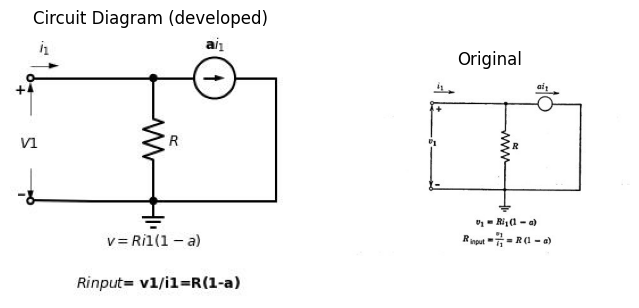

In [16]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

# Create the figure and subplots
fig, axs = plt.subplots(1,2, figsize=(8, 8))
d = schemdraw.Drawing()
l1 = d.add(e.Line().right().length(.0004).dot(open=True))
l2 = d.add(e.Line().right().length(3).dot().at(l1.start))
R1 = d.add(e.Resistor().down().dot().label('$R$', 'bottom'))
I = d.add(e.SourceI(l=3).right().label('a$i_1$').at(R1.start)) 
l3 = d.add(e.Line().down().length(3))
l4 = d.add(e.Line().left().length(3))
l5 = d.add(e.Line().left().length(3).dot(open=True))
d += e.Ground().at(R1.end).label('$v=Ri1(1-a)$', 'bottom')
d += e.Arrow().up().length(0.8).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((0,-0.9))
d += e.Arrow().down().length(0.8).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((0,-2.2))
d += e.Arrow().up().length(1).linewidth(0.6).color('white').label('$V{1}$', loc='start', color='black',ofst=0.3). at((0.5,-1.4))
l6 = d.add(e.Line().right().label('$R{input}$= v1/i1=R(1-a)', 'right').at((1,-5)).length(.0004))
d += e.Arrow().right().linewidth(0.6).length(0.7).color('black').label('$i_1$', loc='top', color='black',ofst=0.2).at((0,0.3))
d.save('Drawings/1-5a.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/1-5a.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/fig1-5.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

## Fig. 1.5. Effect of controlled source on apparent resistance.

Background gained in the study of linear RLC circuits is useful since it
applies directly to nonlinear electronic circuit problems when the devices
are represented by piecewise-linear models. The very fact that piece-
wise-linear approximations provide a facility for handling nonlinear
problems provides a strong stimulus for further study of linear circuit
theory. The more we know about linear circuit theory, the better our
preparation for handling electronic circuit. problems.

The controlled source, though linear, introduces effects not treated in
elementary circuit theory. Figure 1.5 offers a specific example. The
controlled source dicfates the current through R, thereby establishing
v, and determining the apparent input resistance. If we apply The-
venin’s theorem and calculate the effective resistance between terminals
by “short-circuiting the internal voltage sources and open-circuiting the
current sources,’ we obtain the value R, which is incorrect. The error
arises from an incorrect use of Thevenin’s theorem. Only independent
sources may be open-circuited or short-circuited to find effective resistance, since only independent sources contribute to the constant A
(open-circuit voltage) in the general linear terminal relation

$v=A+ Bi$                          $(1.1)$


Controlled sources are dependent on the control signal. Since they
change when the control signal changes, they contribute to the constant.
B (effective resistance). Thus, controlled sources do not violate the
laws of elementary linear circuit theory but they do require us to under-
stand the laws, rules, and theorems in order to apply them properly.

In this book we shall describe certain conduction processes, from these
deduce the terminal behavior of various electronic devices, make circuit
models for the devices, and use the models to study the operation of
basic electronic circuits. Attention is given to the important functions
performed by each class of circuits. As we proceed, it will become clear
that a relatively small number of fundamental ideas, properly inter-
preted, permit one to understand the operation of a very large variety of
electronic devices, circuits, functions, and systems. An integration of
such ideas is the basis for circuit and system design.

**PROBLEMS**

**1.1**. Which of the following terms apply to the ideal diode? (a) linear,
(b) capacitive, (c} resistive, (2) inductive, (e) nonlinear, (f) lossless, (g) bi-
directional, (hk) reactive, (i} passive, (7) active.

**1.2**. Do the following relations between instantaneous current and voltage
specify the behavior of the ideal diode completely?

$$i≤0$$
$$v≥0$$
$$vi=0$$

**1.3**. Compare the following relations with those of Problem 1.2.
$$v=0 fori > 0$$
$$i=0 fory <0$$
**1.4**. What is the circuit model M for a driving-point curve like that shown
in Fig. P1.1?

**1.5**. Sketch the output curve 7; vs. ve for the voltage-controlled voltage
source shown in Fig. P1.2. What are the dimensions of μ?

Text(0.5, 1.0, 'Original')

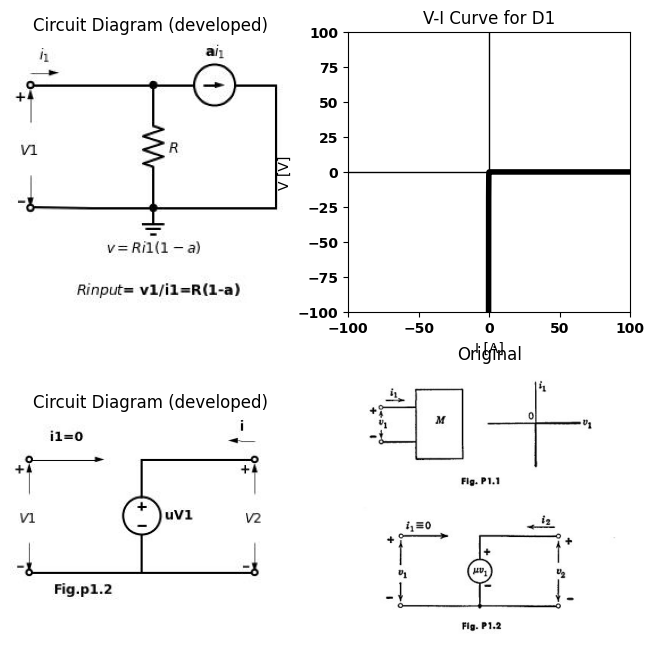

In [22]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

# Create the figure and subplots
fig, axs = plt.subplots(2,2, figsize=(8, 8))
d = schemdraw.Drawing()
d += ( T := dsp.Box(w=2, h=4).anchor('W').fill('white').label('M').label('Fig.p1.1', loc='bottom', color='black',ofst=0.2))
l1 = d.add(e.Line().left().length(3).dot(open=True).at((0,1)))
l2 = d.add(e.Line().left().length(3).dot(open=True).at((0,-1)))
d += e.Arrow().up().length(0.4).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((-3,0.5))
d += e.Arrow().down().length(0.4).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((-3,-.5))
d += e.Arrow().up().length(0.001).linewidth(0.6).color('white').label('$V$', loc='start', color='black',ofst=0.3). at((-2.5,.1))
d += e.Arrow().right().linewidth(0.6).length(0.7).color('black').label('i', loc='top', color='black',ofst=0.2). at((-3,1.5))
d.save('Drawings/p1-1.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/1-5a.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
rcParams['font.weight'] = 'bold'
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 40@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 0.01@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, circuit.gnd, '1' , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0,1].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=4)
# circuit 3
axs[0,1].set_title('V-I Curve for D1')

axs[0,1].set_xlim(-100, 100)
axs[0,1].set_xlabel('I [A]')
axs[0,1].set_ylabel('V [V]')
axs[0,1].set_ylim(-100, 100)
axs[0,1].axhline(0, color='black', linewidth=1)
axs[0,1].axvline(0, color='black', linewidth=1)
d = schemdraw.Drawing()
l1 = d.add(e.Line().right().length(.0004).dot(open=True))
d += e.Arrow().right().length(2).linewidth(1).color('black').label('i1=0',loc='top', color='black',ofst=0.4)
V = d.add( e.SourceV().up().label('uV1', 'bottom').at((3,-3))) 
l2 = d.add(e.Line().right().length(3).dot(open=True))
l3 = d.add(e.Line().right().length(3).dot(open=True).at(V.start))
l4 = d.add(e.Line().left().length(3).dot(open=True).at(V.start).label('Fig.p1.2', loc='bottom', color='black',ofst=0.2))
d += e.Arrow().up().length(0.8).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((0,-0.9))
d += e.Arrow().down().length(0.8).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((0,-2.2))
d += e.Arrow().up().length(1).linewidth(0.6).color('white').label('$V1$', loc='start', color='black',ofst=0.3). at((.5,-1.4))
d += e.Arrow().up().length(0.8).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((6,-0.9))
d += e.Arrow().down().length(0.8).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((6,-2.2))
d += e.Arrow().up().length(1).linewidth(0.6).color('white').label('$V2$', loc='start', color='black',ofst=0.3). at((6.5,-1.4))
d += e.Arrow().left().linewidth(0.6).length(0.7).color('black').label('i', loc='top', color='black',ofst=0.2). at((6,.5))
d.save('Drawings/p1-2.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/p1-2.jpg')
axs[1,0].imshow(img)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**

img_sample = mpimg.imread('images/p1-1.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

## 1.6 Sketch the output curve i: vs. ve for the voltage-controlled current
source shown in Fig. P1.3. What are the dimensions of g?

Text(0.5, 1.0, 'Original')

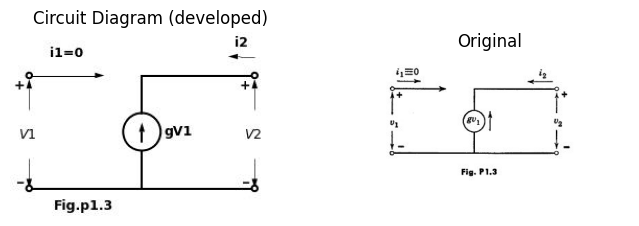

In [24]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

# Create the figure and subplots
fig, axs = plt.subplots(1,2, figsize=(8, 8))
d = schemdraw.Drawing()
l1 = d.add(e.Line().right().length(.0004).dot(open=True))
d += e.Arrow().right().length(2).linewidth(1).color('black').label('i1=0',loc='top', color='black',ofst=0.4)
V = d.add( e.SourceI().up().label('gV1', 'bottom').at((3,-3))) 
l2 = d.add(e.Line().right().length(3).dot(open=True))
l3 = d.add(e.Line().right().length(3).dot(open=True).at(V.start))
l4 = d.add(e.Line().left().length(3).dot(open=True).at(V.start).label('Fig.p1.3', loc='bottom', color='black',ofst=0.2))
d += e.Arrow().up().length(0.8).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((0,-0.9))
d += e.Arrow().down().length(0.8).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((0,-2.2))
d += e.Arrow().up().length(1).linewidth(0.6).color('white').label('$V1$', loc='start', color='black',ofst=0.3). at((.5,-1.4))
d += e.Arrow().up().length(0.8).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((6,-0.9))
d += e.Arrow().down().length(0.8).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((6,-2.2))
d += e.Arrow().up().length(1).linewidth(0.6).color('white').label('$V2$', loc='start', color='black',ofst=0.3). at((6.5,-1.4))
d += e.Arrow().left().linewidth(0.6).length(0.7).color('black').label('i2', loc='top', color='black',ofst=0.2). at((6,.5))
d.save('Drawings/p1-3.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/p1-3.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**

img_sample = mpimg.imread('images/p1-3.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

## 1.7 Sketch the output curve vy vs. ig for the current-controlled voltage
source shown in Fig. P1.4. What are the dimensions of r?

Text(0.5, 1.0, 'Original')

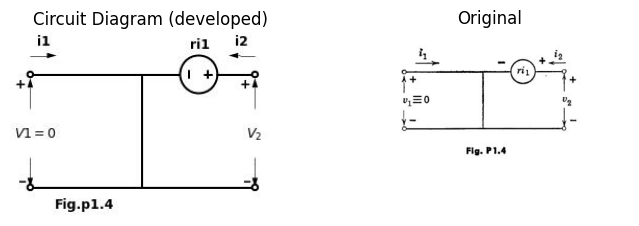

In [25]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

# Create the figure and subplots
fig, axs = plt.subplots(1,2, figsize=(8, 8))
d = schemdraw.Drawing()
l1 = d.add(e.Line().right().length(.0004).dot(open=True))
l2 = d.add(e.Line().right().length(3))
l3 = d.add(e.Line().down().length(3))
l4 = d.add(e.Line().left().length(3).dot(open=True).label('Fig.p1.4', loc='bottom', color='black',ofst=0.2))
V = d.add( e.SourceV().right().label('ri1', 'top').at(l2.end).dot(open=True)) 
l5 = d.add(e.Line().right().length(3).dot(open=True).at(l3.end))
d += e.Arrow().up().length(0.8).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((0,-0.9))
d += e.Arrow().down().length(0.8).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((0,-2.2))
d += e.Arrow().up().length(1).linewidth(0.6).color('white').label('$V1=0$', loc='start', color='black',ofst=0.3). at((1,-1.4))
d += e.Arrow().up().length(0.8).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((6,-0.9))
d += e.Arrow().down().length(0.8).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((6,-2.2))
d += e.Arrow().up().length(1).linewidth(0.6).color('white').label('$V_2$', loc='start', color='black',ofst=0.3). at((6.5,-1.4))
d += e.Arrow().right().linewidth(0.6).length(0.7).color('black').label('i1', loc='top', color='black',ofst=0.2). at((0,.5))
d += e.Arrow().left().linewidth(0.6).length(0.7).color('black').label('i2', loc='top', color='black',ofst=0.2). at((6,.5))
d.save('Drawings/p1-4.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/p1-4.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**

img_sample = mpimg.imread('images/p1-4.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

**1.8**. Plot the terminal relation v vs. 7 for a linear resistance.

**1.9**. Show by graphical addition of voltages that the curve in Fig. 1.3(b) is
composed of the curves for a resistance R and an ideal diode.

**1.10**. Plot the terminal relation v va. i for a linear resistance F in parallel
with an ideal diode.

**1.11** Plot i vs. v for the circuit shown in Fig. P1.5.

Text(0.5, 1.0, 'Original')

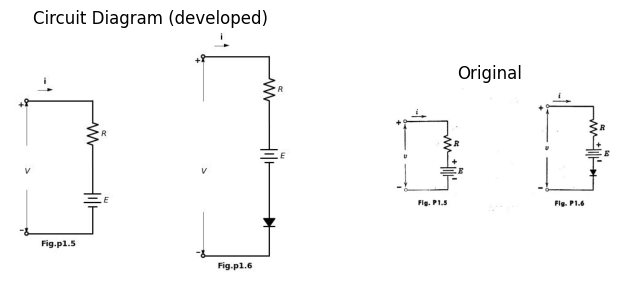

In [26]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

# Create the figure and subplots
fig, axs = plt.subplots(1,2, figsize=(8, 8))
d = schemdraw.Drawing()
l1 = d.add(e.Line().right().length(.0004).dot(open=True))
l2 = d.add(e.Line().right().length(3))
R1 = d.add(e.Resistor().down().label('$R$', 'bottom'))
d += e.Battery().label('$E$', 'bottom').down()
l3 = d.add(e.Line().left().length(3).dot(open=True).label('Fig.p1.5', loc='bottom', color='black',ofst=0.2))
d += e.Arrow().up().length(2).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((0,-2))
d += e.Arrow().down().length(2).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((0,-4))
d += e.Arrow().up().length(1).linewidth(0.6).color('white').label('$V$', loc='start', color='black',ofst=0.3). at((0.5,-3))
d += e.Arrow().right().linewidth(0.6).length(0.7).color('black').label('i', loc='top', color='black',ofst=0.2). at((0.5,0.5))
l4 = d.add(e.Line().right().length(.0004).dot(open=True). at((8,2)))
l5 = d.add(e.Line().right().length(3))
R2 = d.add(e.Resistor().down().label('$R$', 'bottom'))
d += e.Battery().label('$E$', 'bottom').down()
D2 = d.add(e.Diode(fill=True).down())
l6 = d.add(e.Line().left().length(3).dot(open=True).label('Fig.p1.6', loc='bottom', color='black',ofst=0.2))
d += e.Arrow().up().length(2).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((8,0))
d += e.Arrow().down().length(2).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((8,-5))
d += e.Arrow().up().length(1).linewidth(0.6).color('white').label('$V$', loc='start', color='black',ofst=0.3). at((8.5,-3))
d += e.Arrow().right().linewidth(0.6).length(0.7).color('black').label('i', loc='top', color='black',ofst=0.2). at((8.5,2.5))
d.save('Drawings/p1-6.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/p1-6.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**

img_sample = mpimg.imread('images/p1-6.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

**1.12**. Plot i vs. v for the circuit shown in Fig. P1.6.

**1.13**. How can the circuit of Fig. P1.6 be modified to represent the curve of
Fig. 1.4(b) in the text?

C:\MLPack\PortablePython-3.10.5x64\App\Python\lib\site-packages\schemdraw\elements\elements.py:147: UserWarning: Duplicate `at` parameter in element: `Point(5.8,2.0)` changed to `Point(3,-1)`.
  warnings.warn("Duplicate `at` parameter in element: "


Text(0.5, 1.0, 'Original')

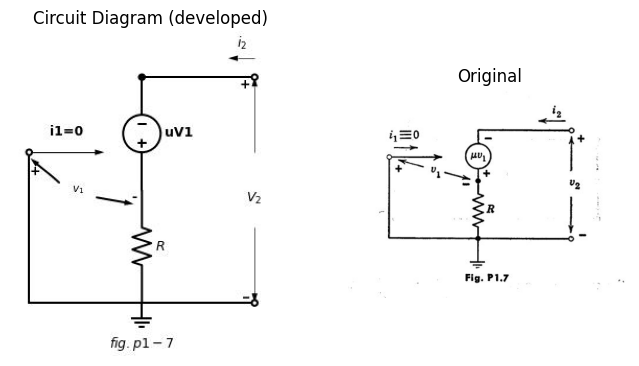

In [33]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
fig, axs = plt.subplots(1,2, figsize=(8, 8))
d = schemdraw.Drawing()
l1 = d.add(e.Line().right().length(.0004).dot(open=True))
d += e.Arrow().right().length(2).linewidth(1).color('black').label('i1=0',loc='top', color='black',ofst=0.4)
V = d.add( e.SourceV().up().label('uV1', 'bottom').at(l2.end).reverse().at((3,-1)).dot()) 
l2 = d.add(e.Line().right().length(3).dot(open=True))
R1 = d.add(e.Resistor().down().label('$R$', 'bottom').at(V.start))
l3 = d.add(e.Line().right().length(3).dot(open=True).at(R1.end))
l4 = d.add(e.Line().left().length(3).at(l3.start))
l5 = d.add(e.Line().up().length(3.9))
d += e.Arrow().length(1).at((.8, -.8)).label('+', ofst=(0.2,0.4)).theta(-220)
d += e.Arrow().length(1).at((1.8, -1.2)).label('-', ofst=(0.5,0)).theta(-10) 
d += e.Gap().right().label('$v_{1}$',fontsize = 12).color('black').at((-.2,-.8))
d += e.Arrow().up().length(2).linewidth(0.6).color('black').label('+',loc='end', color='black',ofst=0.4). at((6,0))
d += e.Arrow().down().length(2).linewidth(0.6).color('black').label(r'_', loc='end', color='black',ofst=(-0.5,-0.3)). at((6,-2))
d += e.Arrow().up().length(1).linewidth(0.6).color('white').label('$V_2$', loc='start', color='black',ofst=0.3). at((6.5,-1))
d += e.Arrow().left().linewidth(0.6).length(0.7).color('black').label('$i_2$', loc='top', color='black',ofst=0.2). at((6,2.5))
d += e.Ground().at(R1.end).label('$fig.p1-7$', loc='bottom', color='black',ofst=0.2)
d.save('Drawings/p1-7.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/p1-7.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p1-7.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

**1.14**. Determine the ratio of v2 to i2  for the cireuit shown in Fig. P1.7.


## Navigation

<!--NAVIGATION-->
( [**TOC**](../TOC.md) | Next: [**2.1 Electrical Conduction and Diodes**](../chapter.2/chapter2.ipynb) )

[**This file as MS Word (docx)**](./Docs/chapter1.docx) 
